# Практична робота 1

## Google Colab, GitHub і перше знайомство з даними

**Дисципліна:** Розпізнавання образів і машинне навчання  
**Студент:** Река Євгеній  
**Група:** ІН-42/2  
**Дата виконання:** 16.11.2026

### Мета роботи

Ознайомитися із середовищем Google Colab, структурою ML-проєкту, сервісом GitHub і базовими операціями аналізу табличних даних.

## 1. Підключення бібліотек

На цьому етапі підключаються бібліотеки для роботи з таблицями, числовими масивами, графіками та наборами даних машинного навчання.

In [5]:
from pathlib import Path
import sys

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import sklearn

from sklearn.datasets import load_iris
from IPython.display import display

Перевірка версій встановлених бібліотек. Версії в різні дні можуть відрізнятися — це не є помилкою.

In [6]:
print("Версія Python:", sys.version.split()[0])
print("Версія NumPy:", np.__version__)
print("Версія pandas:", pd.__version__)
print("Версія scikit-learn:", sklearn.__version__)

Версія Python: 3.13.18
Версія NumPy: 2.4.6
Версія pandas: 2.2.3
Версія scikit-learn: 1.6.1


## 2. Підключення Google Drive

Google Drive використовується для постійного зберігання наборів даних і результатів роботи. Файли у тимчасовій пам'яті Colab можуть бути видалені після завершення сеансу.

In [7]:
from google.colab import drive

drive.mount("/content/drive")

Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).


### 2.1. Створення робочих папок на Google Drive

`mkdir(parents=True, exist_ok=True)` створює папку разом із батьківськими папками і не видає помилку, якщо папка вже існує.

In [8]:
PROJECT_DIR = Path("/content/drive/MyDrive/pattern-recognition-practice")
DATA_DIR = PROJECT_DIR / "data"
NOTEBOOKS_DIR = PROJECT_DIR / "notebooks"
REPORTS_DIR = PROJECT_DIR / "reports"

DATA_DIR.mkdir(parents=True, exist_ok=True)
NOTEBOOKS_DIR.mkdir(parents=True, exist_ok=True)
REPORTS_DIR.mkdir(parents=True, exist_ok=True)

print("Робоча папка:", PROJECT_DIR)
print("Папка даних:", DATA_DIR)
print("Папка Notebook:", NOTEBOOKS_DIR)
print("Папка звітів:", REPORTS_DIR)

Робоча папка: /content/drive/MyDrive/pattern-recognition-practice
Папка даних: /content/drive/MyDrive/pattern-recognition-practice/data
Папка Notebook: /content/drive/MyDrive/pattern-recognition-practice/notebooks
Папка звітів: /content/drive/MyDrive/pattern-recognition-practice/reports


Перевірка створених папок:

In [9]:
for path in PROJECT_DIR.iterdir():
    print(path.name)

data
notebooks
reports


## 3. Завантаження набору даних

У роботі використовується навчальний набір Iris із бібліотеки scikit-learn. Він містить вимірювання квіток трьох видів ірису. Параметр `as_frame=True` повертає дані у вигляді об'єктів pandas.

In [10]:
iris = load_iris(as_frame=True)

print(type(iris))
print(iris.keys())

<class 'sklearn.utils._bunch.Bunch'>
dict_keys(['data', 'target', 'frame', 'target_names', 'DESCR', 'feature_names', 'filename', 'data_module'])


Назви ознак і класів:

In [11]:
print("Назви ознак:")
for feature_name in iris.feature_names:
    print("-", feature_name)

print("\nНазви класів:")
for target_name in iris.target_names:
    print("-", target_name)

Назви ознак:
- sepal length (cm)
- sepal width (cm)
- petal length (cm)
- petal width (cm)

Назви класів:
- setosa
- versicolor
- virginica


Створення DataFrame. Метод `copy()` створює окрему копію таблиці, щоб зміни не впливали на початковий об'єкт.

In [12]:
df = iris.frame.copy()

display(df.head())

,sepal length (cm),sepal width (cm),petal length (cm),petal width (cm),target
0,5.1,3.5,1.4,0.2,0
1,4.9,3.0,1.4,0.2,0
2,4.7,3.2,1.3,0.2,0
3,4.6,3.1,1.5,0.2,0
4,5.0,3.6,1.4,0.2,0


### 3.1. Перетворення числового класу на назву виду

У початковому наборі класи закодовані числами 0, 1, 2. Замінимо їх на назви видів.

In [13]:
print(df["target"].value_counts().sort_index())

target
0    50
1    50
2    50
Name: count, dtype: int64


In [14]:
target_mapping = {
    0: "setosa",
    1: "versicolor",
    2: "virginica"
}

print(target_mapping)

# Нова текстова цільова змінна замість числового стовпця target
df["species"] = df["target"].map(target_mapping)
df = df.drop(columns=["target"])

{0: 'setosa', 1: 'versicolor', 2: 'virginica'}


### 3.2. Перейменування стовпців

In [15]:
df = df.rename(
    columns={
        "sepal length (cm)": "sepal_length_cm",
        "sepal width (cm)": "sepal_width_cm",
        "petal length (cm)": "petal_length_cm",
        "petal width (cm)": "petal_width_cm"
    }
)

display(df.head())

,sepal_length_cm,sepal_width_cm,petal_length_cm,petal_width_cm,species
0,5.1,3.5,1.4,0.2,setosa
1,4.9,3.0,1.4,0.2,setosa
2,4.7,3.2,1.3,0.2,setosa
3,4.6,3.1,1.5,0.2,setosa
4,5.0,3.6,1.4,0.2,setosa


## 4. Збереження даних у форматі CSV

Підготовлена таблиця зберігається на Google Drive, після чого повторно завантажується засобами бібліотеки pandas. Параметр `index=False` забороняє записувати до файла службовий індекс pandas.

In [16]:
CSV_PATH = DATA_DIR / "iris.csv"

df.to_csv(CSV_PATH, index=False)

print("Файл збережено:")
print(CSV_PATH)

Файл збережено:
/content/drive/MyDrive/pattern-recognition-practice/data/iris.csv


In [17]:
if CSV_PATH.exists():
    print("Файл успішно створено.")
    print("Розмір файла:", CSV_PATH.stat().st_size, "байт")
else:
    print("Файл не знайдено.")

Файл успішно створено.
Розмір файла: 3870 байт


## 5. Читання табличних даних

Для читання CSV-файла використовується функція `pandas.read_csv()`. Результатом є об'єкт типу DataFrame.

In [18]:
data = pd.read_csv(CSV_PATH)

print("Тип об'єкта:", type(data))

Тип об'єкта: <class 'pandas.core.frame.DataFrame'>


### 5.1. Перші та останні рядки

`head()` показує перші п'ять рядків, `tail()` — останні п'ять.

In [19]:
display(data.head())

,sepal_length_cm,sepal_width_cm,petal_length_cm,petal_width_cm,species
0,5.1,3.5,1.4,0.2,setosa
1,4.9,3.0,1.4,0.2,setosa
2,4.7,3.2,1.3,0.2,setosa
3,4.6,3.1,1.5,0.2,setosa
4,5.0,3.6,1.4,0.2,setosa


In [20]:
display(data.tail())

,sepal_length_cm,sepal_width_cm,petal_length_cm,petal_width_cm,species
145,6.7,3.0,5.2,2.3,virginica
146,6.3,2.5,5.0,1.9,virginica
147,6.5,3.0,5.2,2.0,virginica
148,6.2,3.4,5.4,2.3,virginica
149,5.9,3.0,5.1,1.8,virginica


### 5.2. Розмір таблиці та назви стовпців

Перший елемент `shape` — кількість рядків, другий — кількість стовпців.

In [21]:
print("Розмір таблиці:", data.shape)
print("Кількість об'єктів:", data.shape[0])
print("Кількість стовпців:", data.shape[1])

Розмір таблиці: (150, 5)
Кількість об'єктів: 150
Кількість стовпців: 5


In [22]:
print("Назви стовпців:")

for column in data.columns:
    print("-", column)

Назви стовпців:
- sepal_length_cm
- sepal_width_cm
- petal_length_cm
- petal_width_cm
- species


### 5.3. Типи даних і загальна інформація

In [23]:
print(data.dtypes)

sepal_length_cm    float64
sepal_width_cm     float64
petal_length_cm    float64
petal_width_cm     float64
species             object
dtype: object


In [24]:
data.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 150 entries, 0 to 149
Data columns (total 5 columns):
 #   Column           Non-Null Count  Dtype  
---  ------           --------------  -----  
 0   sepal_length_cm  150 non-null    float64
 1   sepal_width_cm   150 non-null    float64
 2   petal_length_cm  150 non-null    float64
 3   petal_width_cm   150 non-null    float64
 4   species          150 non-null    object 
dtypes: float64(4), object(1)
memory usage: 6.0+ KB


### 5.4. Пропущені значення, дублікати та унікальні значення

In [25]:
missing_values = data.isna().sum()

print("Кількість пропущених значень:")
print(missing_values)
print("Загальна кількість пропусків:", data.isna().sum().sum())

Кількість пропущених значень:
sepal_length_cm    0
sepal_width_cm     0
petal_length_cm    0
petal_width_cm     0
species            0
dtype: int64
Загальна кількість пропусків: 0


In [26]:
duplicate_count = data.duplicated().sum()

print("Кількість повністю однакових рядків:", duplicate_count)

Кількість повністю однакових рядків: 1


In [27]:
print("Кількість унікальних значень у кожному стовпці:")
print(data.nunique())

Кількість унікальних значень у кожному стовпці:
sepal_length_cm    35
sepal_width_cm     23
petal_length_cm    43
petal_width_cm     22
species             3
dtype: int64


### 5.5. Зведена таблиця структури даних

In [28]:
structure_summary = pd.DataFrame(
    {
        "data_type": data.dtypes.astype(str),
        "missing_values": data.isna().sum(),
        "unique_values": data.nunique()
    }
)

display(structure_summary)

,data_type,missing_values,unique_values
sepal_length_cm,float64,0,35
sepal_width_cm,float64,0,23
petal_length_cm,float64,0,43
petal_width_cm,float64,0,22
species,object,0,3


**Пояснення до таблиці структури:**

- Числові стовпці (тип `float64`): `sepal_length_cm`, `sepal_width_cm`, `petal_length_cm`, `petal_width_cm`.
- Категоріальний стовпець (текстовий тип): `species` — вид ірису.
- Пропущених значень немає у жодному стовпці.
- Найменше унікальних значень має `species` — лише 3 (це класи). Серед числових ознак найменше унікальних значень у `petal_width_cm` (22) і `sepal_width_cm` (23), бо вимірювання записані з точністю до 0,1 см.
- Знайдено 1 повністю однаковий рядок (дві квітки virginica з однаковими вимірами). Його не видаляємо, лише фіксуємо.

## 6. Описова статистика

`describe()` для числових стовпців показує кількість значень, середнє, стандартне відхилення, мінімум, квартилі (25 %, 50 % — медіана, 75 %) і максимум. `.T` транспонує таблицю для зручного перегляду.

In [29]:
numeric_statistics = data.describe().T

display(numeric_statistics)

,count,mean,std,min,25%,50%,75%,max
sepal_length_cm,150.0,5.843333,0.828066,4.3,5.1,5.80,6.4,7.9
sepal_width_cm,150.0,3.057333,0.435866,2.0,2.8,3.00,3.3,4.4
petal_length_cm,150.0,3.758000,1.765298,1.0,1.6,4.35,5.1,6.9
petal_width_cm,150.0,1.199333,0.762238,0.1,0.3,1.30,1.8,2.5


### 6.1. Статистика цільової змінної

In [30]:
class_counts = data["species"].value_counts()

display(class_counts.rename("count").to_frame())

,count
species,
setosa,50
versicolor,50
virginica,50


In [31]:
class_percentages = (
    data["species"]
    .value_counts(normalize=True)
    .mul(100)
    .round(2)
)

display(class_percentages.rename("percentage").to_frame())

,percentage
species,
setosa,33.33
versicolor,33.33
virginica,33.33


## 7. Візуалізація даних

Гістограми використовуються для первинного дослідження розподілів числових ознак.

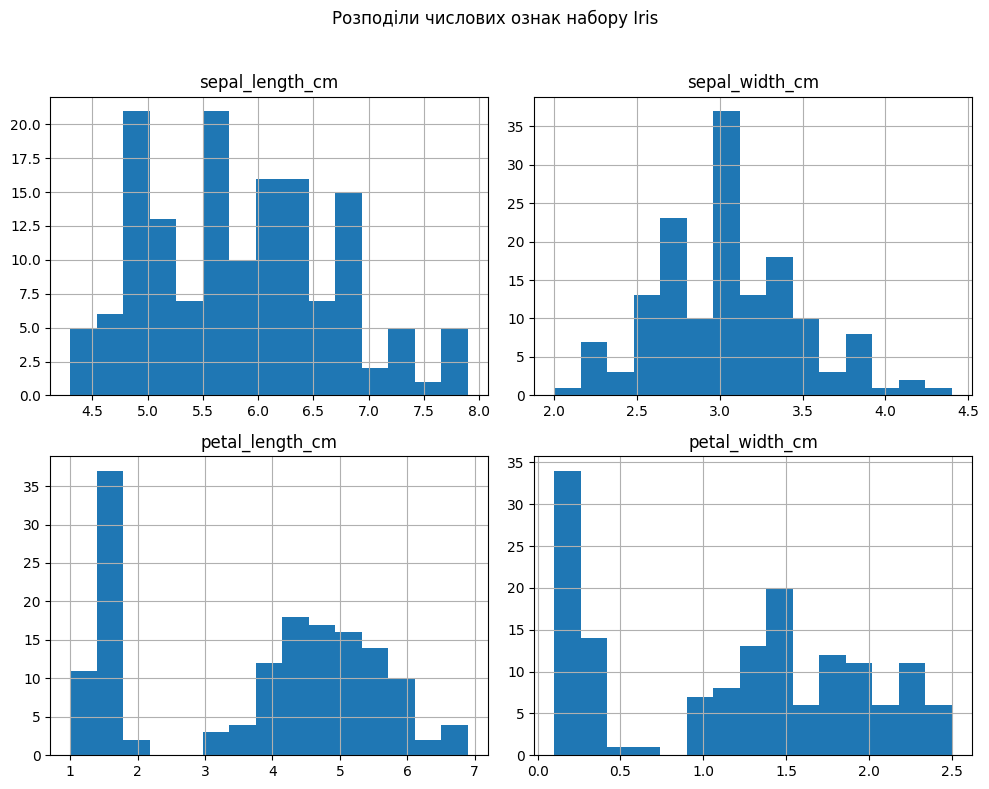

In [32]:
feature_columns = [
    "sepal_length_cm",
    "sepal_width_cm",
    "petal_length_cm",
    "petal_width_cm"
]

data[feature_columns].hist(
    bins=15,
    figsize=(10, 8)
)

plt.suptitle("Розподіли числових ознак набору Iris")
plt.tight_layout(rect=[0, 0, 1, 0.96])
plt.show()

**Аналіз гістограм:**

1. **Найменші значення** має ознака `petal_width_cm` (ширина пелюстки): від 0,1 до 2,5 см.
2. **Найбільший діапазон** має `petal_length_cm` (довжина пелюстки): від 1,0 до 6,9 см, тобто 5,9 см.
3. **Форма розподілів різна.** Ознаки чашолистка (`sepal_length_cm`, `sepal_width_cm`) мають один пік і схожі на нормальний розподіл. Ознаки пелюстки розподілені нерівномірно і мають розрив.
4. **Кілька груп значень** видно у `petal_length_cm` і `petal_width_cm`: окрема група малих значень (довжина приблизно 1–2 см, ширина 0,1–0,6 см) і друга група більших значень. Найімовірніше, мала група — це один вид ірису.

### 7.1. Розподіл об'єктів за класами

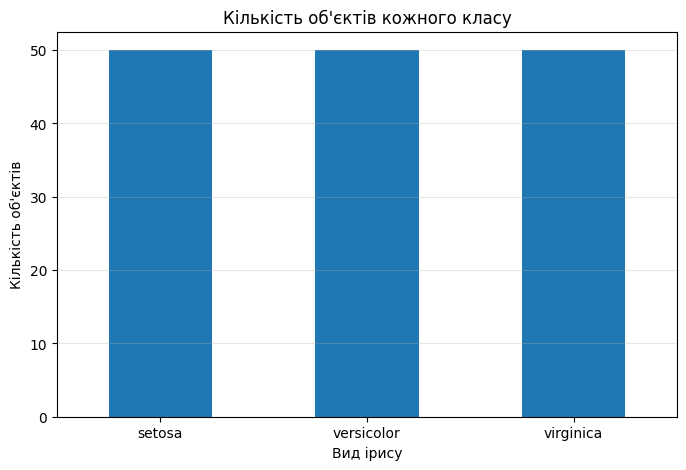

In [33]:
class_counts = data["species"].value_counts().sort_index()

class_counts.plot(
    kind="bar",
    figsize=(8, 5)
)

plt.title("Кількість об'єктів кожного класу")
plt.xlabel("Вид ірису")
plt.ylabel("Кількість об'єктів")
plt.xticks(rotation=0)
plt.grid(axis="y", alpha=0.3)
plt.show()

**Чи є набір даних збалансованим?** Так. Кожен із трьох класів містить рівно 50 об'єктів (по 33,33 %), тому набір повністю збалансований.

### 7.2. Діаграма залежності довжини та ширини пелюстки

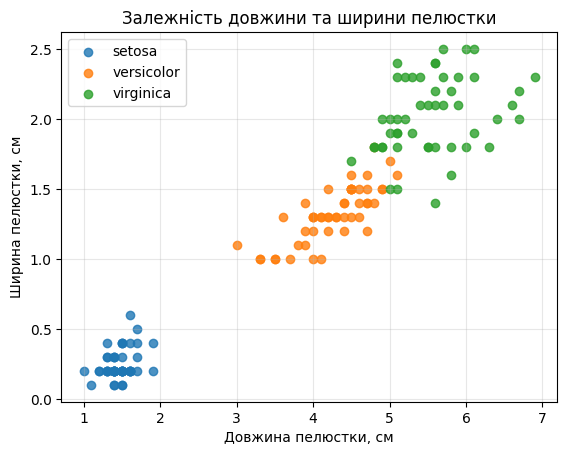

In [34]:
# Кожен вид малюємо окремим кольором, щоб побачити групи
for species_name, group in data.groupby("species"):
    plt.scatter(
        group["petal_length_cm"],
        group["petal_width_cm"],
        label=species_name,
        alpha=0.8
    )

plt.title("Залежність довжини та ширини пелюстки")
plt.xlabel("Довжина пелюстки, см")
plt.ylabel("Ширина пелюстки, см")
plt.legend()
plt.grid(alpha=0.3)
plt.show()

**Аналіз діаграми:**

1. **Так, об'єкти різних класів утворюють окремі групи.** Точки кожного виду зосереджені у своїй області.
2. **Найкраще відокремлюється setosa.** Її пелюстки короткі (до 2 см) і вузькі (до 0,6 см), а група лежить далеко від інших.
3. **Частково перекриваються versicolor і virginica**, приблизно в області довжини пелюстки 4,5–5,1 см і ширини 1,5–1,8 см.
4. **Так, ці ознаки можна використати для розпізнавання виду.** Setosa визначається майже безпомилково, а versicolor і virginica розрізняються в більшості випадків, крім зони перекриття.

## 8. Постановка задачі машинного навчання

### Об'єкт дослідження

Одним об'єктом є одна квітка ірису, для якої виміряно характеристики чашолистка та пелюстки.

### Ознаки

Використовуються чотири числові ознаки:

1. довжина чашолистка;
2. ширина чашолистка;
3. довжина пелюстки;
4. ширина пелюстки.

### Цільова змінна

Цільовою змінною є `species` – вид квітки ірису.

### Тип задачі

Задача належить до навчання з учителем і є задачею багатокласової класифікації.

### Формулювання задачі

Необхідно за чотирма числовими характеристиками квітки автоматично визначити, до якого з трьох видів ірису вона належить: setosa, versicolor або virginica.

### 8.1. Програмне розділення ознак і цільової змінної

На цьому етапі моделі ще не навчаються. `X` — матриця ознак, `y` — цільова змінна.

In [35]:
X = data.drop(columns=["species"])
y = data["species"]

print("Розмір матриці ознак X:", X.shape)
print("Розмір цільової змінної y:", y.shape)

Розмір матриці ознак X: (150, 4)
Розмір цільової змінної y: (150,)


In [36]:
display(X.head())

,sepal_length_cm,sepal_width_cm,petal_length_cm,petal_width_cm
0,5.1,3.5,1.4,0.2
1,4.9,3.0,1.4,0.2
2,4.7,3.2,1.3,0.2
3,4.6,3.1,1.5,0.2
4,5.0,3.6,1.4,0.2


In [37]:
display(y.head())

,species
0,setosa
1,setosa
2,setosa
3,setosa
4,setosa


## 9. Автоматична перевірка правильності результату

Якщо будь-яка умова не виконується, `assert` зупиняє виконання з помилкою `AssertionError`.

In [38]:
expected_columns = {
    "sepal_length_cm",
    "sepal_width_cm",
    "petal_length_cm",
    "petal_width_cm",
    "species"
}

assert data.shape == (150, 5), (
    f"Очікувався розмір (150, 5), отримано {data.shape}"
)

assert set(data.columns) == expected_columns, (
    "Назви стовпців не відповідають очікуваним."
)

assert data.isna().sum().sum() == 0, (
    "У таблиці знайдено пропущені значення."
)

assert data["species"].nunique() == 3, (
    "Очікувалося три класи."
)

assert set(data["species"].unique()) == {
    "setosa",
    "versicolor",
    "virginica"
}, "Назви класів не відповідають очікуваним."

print("Усі основні перевірки виконано успішно.")

Усі основні перевірки виконано успішно.


## 10. Додаткове завдання (варіант 1)

Діаграма залежності довжини чашолистка (`sepal_length_cm`) від його ширини (`sepal_width_cm`) для трьох видів ірису.

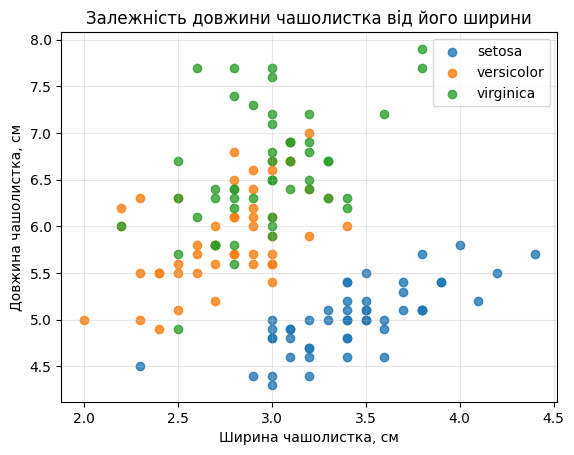

In [39]:
for species_name, group in data.groupby("species"):
    plt.scatter(
        group["sepal_width_cm"],
        group["sepal_length_cm"],
        label=species_name,
        alpha=0.8
    )

plt.title("Залежність довжини чашолистка від його ширини")
plt.xlabel("Ширина чашолистка, см")
plt.ylabel("Довжина чашолистка, см")
plt.legend()
plt.grid(alpha=0.3)
plt.show()

**Висновок до діаграми:** setosa і тут утворює окрему групу: у неї короткі, але широкі чашолистки. Versicolor і virginica за ознаками чашолистка сильно перекриваються, тому для їх розрізнення ознаки пелюстки підходять значно краще.

# Висновки

Під час виконання практичної роботи було створено GitHub-репозиторій для зберігання матеріалів курсу та сформовано базову структуру ML-проєкту.

У середовищі Google Colab було підключено бібліотеки NumPy, pandas, Matplotlib і scikit-learn, а також підключено Google Drive. Для дослідження використано набір даних Iris, який містить 150 об'єктів, чотири числові ознаки та одну цільову категоріальну змінну. Об'єктом дослідження є квітка ірису, а цільовою змінною – її вид. Під час первинного аналізу було визначено розмір таблиці, назви стовпців, типи даних, кількість пропущених значень і основні статистичні характеристики. Також було побудовано гістограми ознак, діаграму кількості об'єктів кожного класу та діаграму залежності довжини й ширини пелюстки.

Встановлено, що досліджувана задача є задачею багатокласової класифікації: за чотирма числовими ознаками необхідно визначити один із трьох видів ірису.

**Власні спостереження:**

- Пропущених значень у наборі немає. Виявлено один повністю однаковий рядок, який на цьому етапі не видалявся.
- Класи повністю збалансовані: по 50 об'єктів (33,33 %) у кожному.
- Найкраще розділяють класи ознаки пелюстки — `petal_length_cm` і `petal_width_cm`. На їхніх гістограмах видно окремі групи значень, а на діаграмі розсіювання кожен вид займає свою область.
- Setosa відокремлюється від інших видів повністю. Versicolor і virginica частково перекриваються на діаграмі пелюсток, а за ознаками чашолистка перекриваються ще сильніше.

# Відповіді на контрольні запитання

1. **Що таке Google Colab?** Хмарне середовище від Google, у якому можна створювати й запускати Jupyter Notebook у браузері без встановлення Python на комп'ютер.

2. **Що таке Jupyter Notebook?** Інтерактивний документ (файл `.ipynb`), що поєднує комірки з кодом, результати їх виконання (таблиці, графіки) і текстові пояснення.

3. **Які два основні типи комірок використовуються в Notebook?** Комірки з кодом (Code) і текстові комірки (Text / Markdown).

4. **Як запустити комірку?** Кнопкою запуску ліворуч від комірки або комбінацією клавіш Shift + Enter.

5. **Для чого призначений файл README.md?** Це основний опис репозиторію: назва, автор, призначення, структура, опис робіт, інструкція із запуску. Його першим бачить користувач на GitHub.

6. **Що таке pandas DataFrame?** Двовимірна таблиця бібліотеки pandas з іменованими стовпцями та індексом рядків. Різні стовпці можуть мати різні типи даних.

7. **Що є рядком таблиці?** Один об'єкт (приклад) — у наборі Iris це одна квітка.

8. **Що є стовпцем таблиці?** Одна характеристика (ознака) всіх об'єктів або цільова змінна.

9. **Що таке об'єкт у задачі машинного навчання?** Один досліджуваний приклад, який описується набором ознак і відповідає одному рядку таблиці.

10. **Що таке ознака?** Вимірювана характеристика об'єкта, якій відповідає окремий стовпець таблиці.

11. **Що таке цільова змінна?** Значення, яке модель має навчитися прогнозувати за ознаками.

12. **Що є об'єктом у наборі Iris?** Одна квітка ірису.

13. **Які ознаки містить набір Iris?** Довжина й ширина чашолистка, довжина й ширина пелюстки (усі в сантиметрах).

14. **Яка цільова змінна використовується у роботі?** `species` — вид ірису.

15. **Чому задача Iris є задачею класифікації?** Цільова змінна є категорією (вид квітки), а не числом, тож потрібно віднести об'єкт до одного зі скінченного набору класів.

16. **Чому ця задача є багатокласовою?** Класів більше двох — три: setosa, versicolor і virginica.

17. **Для чого використовується метод head()?** Для виведення перших рядків таблиці (за замовчуванням п'яти).

18. **Для чого використовується метод tail()?** Для виведення останніх рядків таблиці (за замовчуванням п'яти).

19. **Що повертає властивість shape?** Кортеж (кількість рядків, кількість стовпців). Для Iris це (150, 5).

20. **Для чого використовується метод info()?** Показує кількість рядків, назви стовпців, кількість непорожніх значень, типи даних і обсяг пам'яті.

21. **Яку інформацію повертає метод describe()?** Для числових стовпців: count, mean, std, min, 25 %, 50 % (медіану), 75 % і max.

22. **Як знайти пропущені значення?** За допомогою `data.isna().sum()` (по стовпцях) або `data.isna().sum().sum()` (загальна кількість).

23. **Як перевірити наявність дублікатів?** За допомогою `data.duplicated().sum()` — кількість рядків, які повністю повторюють попередні.

24. **Для чого використовуються гістограми?** Щоб побачити розподіл значень числової ознаки: діапазон, форму розподілу, піки, групи значень і викиди.

25. **Чому важливо аналізувати розподіл об'єктів за класами?** Щоб з'ясувати, чи збалансований набір. Якщо один клас переважає, модель може «звикнути» прогнозувати саме його, а метрика accuracy буде оманливою.

26. **Чим ознаки X відрізняються від цільової змінної y?** X — вхідні дані (матриця ознак, з якої робиться прогноз), y — те, що потрібно спрогнозувати (правильні відповіді).

27. **Чому важливі дані потрібно зберігати на Google Drive або GitHub?** Середовище Colab тимчасове: після завершення або перезапуску сеансу файли і змінні з нього зникають.

28. **Чому перед здаванням необхідно повторно виконати всі комірки?** Щоб переконатися, що Notebook працює зверху вниз без помилок, а всі результати й графіки збережені у файлі.

29. **Які файли містить створений навчальний ML-проєкт?** `README.md`, `.gitignore`, папку `notebooks/` (README.md і цей Notebook), `data/` (README.md і iris.csv) та `reports/` (README.md).